# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Tanti Eka Lestari
- **Email:** ds297b6x1983@student.devacademy.id
- **ID Dicoding:** ds297b6x1983

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".


- **Pertanyaan 1:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan musim (Spring, Summer, Fall, dan Winter) selama periode Januari 2011 hingga Desember 2012, serta musim apa yang memiliki tingkat penyewaan tertinggi?

- **Pertanyaan 2:** Bagaimana pengaruh kondisi cuaca (Clear, Mist/Cloudy, dan Light Rain/Snow) terhadap rata-rata jumlah penyewaan sepeda selama periode Januari 2011 hingga Desember 2012?


## Import Semua Packages/Library yang Digunakan

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan visualisasi
sns.set_theme(style="whitegrid")

# Mengatur tampilan kolom DataFrame
pd.set_option('display.max_columns', None)


## Data Wrangling

### Gathering Data

#### Memuat Dataset Bike Sharing

In [2]:
df = pd.read_csv("day.csv")

df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Dataset berhasil dimuat dengan nama DataFrame `df`.
- Dataset memiliki 731 baris dan 16 kolom.
- Data mencatat jumlah penyewaan sepeda harian dari 1 Januari 2011 sampai 31 Desember 2012.
- Kolom `cnt` menunjukkan total jumlah sepeda yang disewa setiap harinya.

### Assessing Data

#### Mengidentifikasi Masalah pada Dataset

In [3]:
# Melihat informasi dataset
df.info()

# Memeriksa missing values
print("Missing Values:")
print(df.isnull().sum())

# Memeriksa data duplikat
print("Jumlah Data Duplikat:", df.duplicated().sum())

# Memeriksa statistik deskriptif
display(df.describe())

# Memeriksa jumlah penyewaan yang tidak valid
print("Jumlah cnt negatif:", (df['cnt'] < 0).sum())

# Memeriksa kesesuaian total penyewaan
print("Data cnt tidak sesuai casual + registered:",
      (df['cnt'] != df['casual'] + df['registered']).sum())

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB
Missing Values:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday     

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


Jumlah cnt negatif: 0
Data cnt tidak sesuai casual + registered: 0


**Steps to Take:**
- Mengubah tipe data kolom `dteday` menjadi datetime agar dapat digunakan untuk analisis berdasarkan tanggal.
- Memeriksa kembali nilai pada kolom kategorikal seperti `season` dan `weathersit`.
- Memastikan tidak terdapat missing values dan data duplikat.
- Memastikan jumlah penyewaan (`cnt`) sesuai dengan penjumlahan penyewaan casual dan registered.

**Insight:** (Opsional)
- Dataset memiliki 731 baris dan 16 kolom.
- Tidak ditemukan missing values pada dataset.
- Tidak ditemukan data duplikat.
- Kolom `dteday` masih memiliki tipe data object sehingga perlu diubah menjadi datetime.
- Tidak ditemukan nilai negatif pada kolom `cnt`.
- Jumlah penyewaan pada kolom `cnt` sesuai dengan penjumlahan kolom `casual` dan `registered`.

### Cleaning Data

#### Membersihkan dan Memperbaiki Data

In [4]:
# Mengubah tipe data tanggal
df['dteday'] = pd.to_datetime(df['dteday'])

# Mengubah kode musim menjadi nama musim
season_mapping = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

df['season'] = df['season'].map(season_mapping)

# Mengubah kode kondisi cuaca menjadi nama kondisi cuaca
weather_mapping = {
    1: 'Clear',
    2: 'Mist/Cloudy',
    3: 'Light Rain/Snow',
    4: 'Heavy Rain/Snow'
}

df['weathersit'] = df['weathersit'].map(weather_mapping)

# Memeriksa hasil cleaning
df.info()

display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[us]
 2   season      731 non-null    str           
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    str           
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[us](1), float64(4), int

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Spring,0,1,0,6,0,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Spring,0,1,0,0,0,Mist/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Spring,0,1,0,1,1,Clear,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Spring,0,1,0,2,1,Clear,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Spring,0,1,0,3,1,Clear,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Kolom `dteday` berhasil diubah menjadi tipe data datetime.
- Kode pada kolom `season` berhasil diubah menjadi nama musim agar lebih mudah dipahami.
- Kode pada kolom `weathersit` berhasil diubah menjadi kategori kondisi cuaca.
- Dataset siap digunakan untuk proses analisis dan visualisasi.

## Exploratory Data Analysis (EDA)

### Eksplorasi Data Penyewaan Sepeda

In [5]:
# Rata-rata penyewaan berdasarkan musim
season_analysis = df.groupby('season')['cnt'].agg(
    ['mean', 'sum', 'count']
).sort_values(by='mean', ascending=False)

display(season_analysis)

# Rata-rata penyewaan berdasarkan kondisi cuaca
weather_analysis = df.groupby('weathersit')['cnt'].agg(
    ['mean', 'sum', 'count']
).sort_values(by='mean', ascending=False)

display(weather_analysis)

# Rata-rata penyewaan berdasarkan bulan
monthly_analysis = df.groupby('mnth')['cnt'].mean()

display(monthly_analysis)

# Rata-rata penyewaan berdasarkan hari kerja
workingday_analysis = df.groupby('workingday')['cnt'].mean()

display(workingday_analysis)

,mean,sum,count
season,,,
Fall,5644.303191,1061129,188
Summer,4992.331522,918589,184
Winter,4728.162921,841613,178
Spring,2604.132597,471348,181


,mean,sum,count
weathersit,,,
Clear,4876.786177,2257952,463
Mist/Cloudy,4035.862348,996858,247
Light Rain/Snow,1803.285714,37869,21


mnth
1     2176.338710
2     2655.298246
3     3692.258065
4     4484.900000
5     5349.774194
6     5772.366667
7     5563.677419
8     5664.419355
9     5766.516667
10    5199.225806
11    4247.183333
12    3403.806452
Name: cnt, dtype: float64

workingday
0    4330.168831
1    4584.820000
Name: cnt, dtype: float64

**Insight:** (Opsional)
- Musim Fall memiliki rata-rata penyewaan sepeda tertinggi, yaitu sekitar 5.644 penyewaan per hari.
- Musim Spring memiliki rata-rata penyewaan terendah, yaitu sekitar 2.604 penyewaan per hari.
- Kondisi cuaca Clear memiliki rata-rata penyewaan tertinggi, yaitu sekitar 4.877 penyewaan per hari.
- Kondisi Light Rain/Snow memiliki rata-rata penyewaan terendah, yaitu sekitar 1.803 penyewaan per hari.
- Berdasarkan bulan, rata-rata penyewaan tertinggi terjadi pada bulan Juni.
- Rata-rata penyewaan pada hari kerja sedikit lebih tinggi dibandingkan hari non-kerja.

## Visualization & Explanatory Analysis

### Pertanyaan 1:
Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan musim (Spring, Summer, Fall, dan Winter) selama periode Januari 2011 hingga Desember 2012?

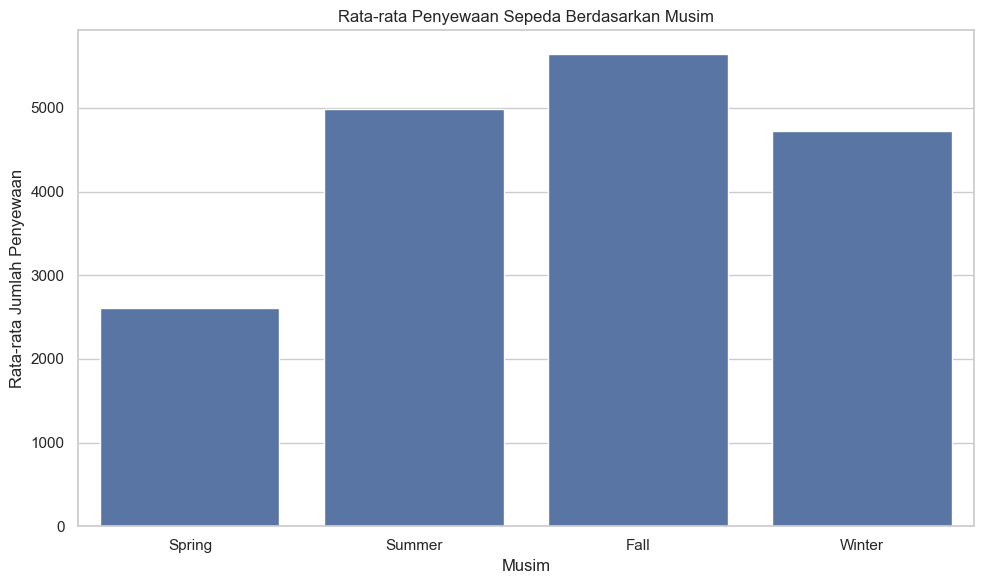

In [6]:
# Menghitung rata-rata penyewaan berdasarkan musim
season_order = ['Spring', 'Summer', 'Fall', 'Winter']

season_avg = df.groupby('season')['cnt'].mean()
season_avg = season_avg.reindex(season_order)

# Membuat visualisasi
plt.figure(figsize=(10, 6))

sns.barplot(
    x=season_avg.index,
    y=season_avg.values
)

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Musim')
plt.xlabel('Musim')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Pertanyaan 2:
Bagaimana pengaruh kondisi cuaca (Clear, Mist/Cloudy, dan Light Rain/Snow) terhadap rata-rata jumlah penyewaan sepeda selama periode Januari 2011 hingga Desember 2012?

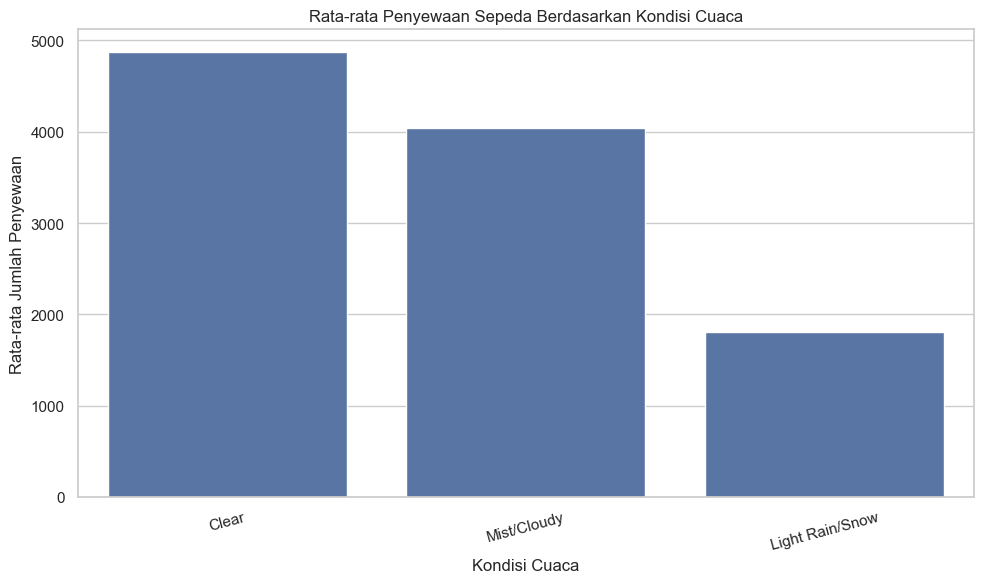

In [7]:
# Menghitung rata-rata penyewaan berdasarkan kondisi cuaca
weather_avg = df.groupby('weathersit')['cnt'].mean()

weather_order = [
    'Clear',
    'Mist/Cloudy',
    'Light Rain/Snow'
]

weather_avg = weather_avg.reindex(weather_order)

# Membuat visualisasi
plt.figure(figsize=(10, 6))

sns.barplot(
    x=weather_avg.index,
    y=weather_avg.values
)

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca')
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)

- Berdasarkan visualisasi pertama, musim Fall memiliki rata-rata penyewaan sepeda tertinggi dibandingkan musim lainnya. Sementara itu, musim Spring memiliki rata-rata penyewaan terendah.
- Hal ini menunjukkan bahwa musim memiliki hubungan dengan tingkat penyewaan sepeda. Jumlah penyewaan cenderung lebih tinggi pada musim Fall dan lebih rendah pada musim Spring.
- Berdasarkan visualisasi kedua, kondisi cuaca Clear memiliki rata-rata penyewaan sepeda tertinggi.
- Kondisi Light Rain/Snow memiliki rata-rata penyewaan paling rendah.
- Hal ini menunjukkan bahwa kondisi cuaca yang lebih baik cenderung diikuti oleh jumlah penyewaan sepeda yang lebih tinggi.

## Analisis Lanjutan (Opsional)

,casual,registered
Non-Working Day,1371.134199,2959.034632
Working Day,606.570000,3978.250000


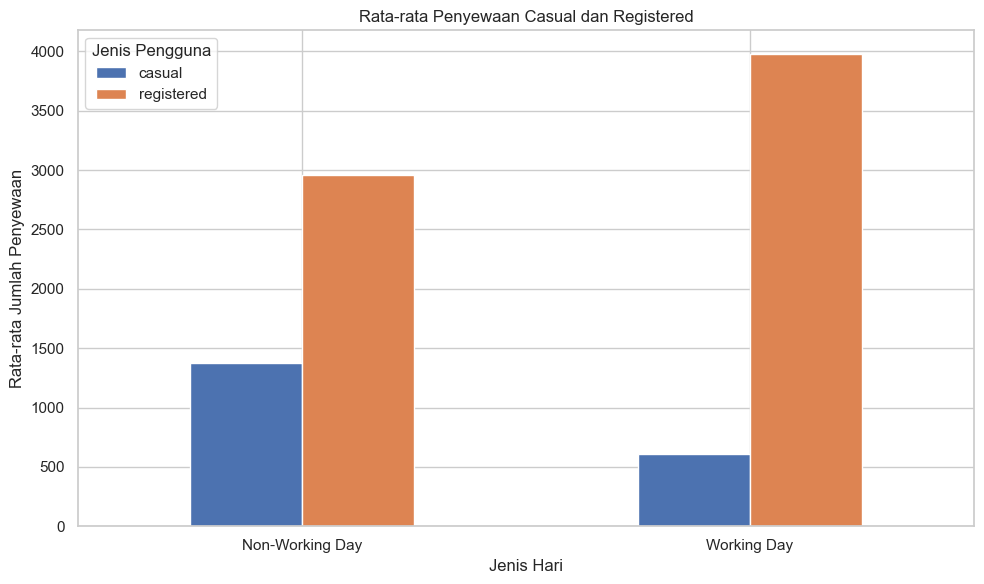

In [8]:
# Mengelompokkan penyewaan berdasarkan hari kerja
workingday_df = df.groupby('workingday')[['casual', 'registered']].mean()

workingday_df.index = [
    'Non-Working Day',
    'Working Day'
]

display(workingday_df)

# Membuat visualisasi
workingday_df.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Rata-rata Penyewaan Casual dan Registered')
plt.xlabel('Jenis Hari')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(rotation=0)
plt.legend(title='Jenis Pengguna')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pada hari kerja, jumlah penyewaan oleh pengguna registered lebih tinggi dibandingkan pengguna casual.
- Pada hari non-kerja, jumlah penyewaan oleh pengguna casual mengalami peningkatan.
- Hal ini menunjukkan bahwa pengguna registered cenderung menggunakan sepeda untuk aktivitas rutin, sedangkan pengguna casual lebih banyak melakukan penyewaan pada hari libur atau non-kerja.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**
  Berdasarkan hasil analisis, musim Fall memiliki rata-rata penyewaan sepeda tertinggi, yaitu sekitar 5.644 penyewaan per hari. Sementara itu, musim Spring memiliki rata-rata penyewaan terendah, yaitu sekitar 2.604 penyewaan per hari. Hal ini menunjukkan bahwa musim memiliki hubungan dengan tingkat penyewaan sepeda. Perbedaan kondisi pada setiap musim dapat menjadi salah satu faktor yang berkaitan dengan perubahan jumlah penyewaan.

- **Conclusion pertanyaan 2:**
  Berdasarkan hasil analisis, kondisi cuaca Clear memiliki rata-rata penyewaan tertinggi, yaitu sekitar 4.877 penyewaan per hari. Kondisi Mist/Cloudy memiliki rata-rata sekitar 4.036 penyewaan per hari, sedangkan Light Rain/Snow memiliki rata-rata terendah, yaitu sekitar 1.803 penyewaan per hari. Hal ini menunjukkan bahwa kondisi cuaca yang kurang baik cenderung diikuti penurunan jumlah penyewaan sepeda.

- **Conclusion analisis lanjutan:**
  Pengguna registered lebih banyak menyewa sepeda pada hari kerja, sedangkan pengguna casual memiliki rata-rata penyewaan lebih tinggi pada hari non-kerja. Hal ini menunjukkan adanya perbedaan pola penggunaan sepeda berdasarkan jenis pengguna dan jenis hari.

**Rekomendasi Action Item:**

- Meningkatkan ketersediaan sepeda pada musim Fall karena musim tersebut memiliki rata-rata penyewaan tertinggi.
- Melakukan promosi khusus pada musim Spring untuk meningkatkan jumlah penyewaan ketika permintaan cenderung lebih rendah.
- Memberikan promosi atau potongan harga pada kondisi cuaca yang kurang mendukung agar pengguna tetap tertarik menyewa sepeda.
- Menambah ketersediaan sepeda dan memperhatikan kebutuhan pengguna registered pada hari kerja.
- Membuat paket penyewaan khusus untuk pengguna casual pada hari libur atau non-kerja.